In [1]:
import os
import re
import json
import numpy as np
import pandas as pd
import torch
import glob
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score

INPUT = "/kaggle/input/datasets/nocturnalnerd18"
OUT_DIR = "/kaggle/working"
SOURCES = {"llava": ("modes-references-llava", "atp-llava-noising"), "qwen": ("modes-references-qwen", "atp-qwen-noising")}
TYPES = ["attribute", "relation"]
MODES = ["image-flipped", "image-amplified", "prior-only", "under-rescued"]
IMAGE = ["image-flipped", "image-amplified"]
TAU = 1.0
MIN_WORD = 25
N_BOOT = 500
rng = np.random.default_rng(1)

with open(f"{INPUT}/vlm-questions/all_questions.json") as f:
    qtext = {q["question_id"]: q["question_text"] for q in json.load(f)}

FRAMES, ORIGINAL = {}, {}
for model_, (slug, atp) in SOURCES.items():
    path = f"{INPUT}/{slug}/references.csv"
    if not os.path.exists(path):
        print(f"{model_}: {slug} not attached, skipped")
        continue
    d = pd.read_csv(path)
    d = d[d.ok].copy()
    orig = {}
    for p in glob.glob(f"{INPUT}/{atp}/**/*_batch_*.pt", recursive=True):
        for e in torch.load(p, weights_only=False):
            if e["ok"]:
                orig[e["question_id"]] = e["delta_corrupt"]
    d["delta_noise_original"] = d.question_id.map(orig)
    FRAMES[model_] = d
    REFS = [c.replace("delta_", "") for c in d.columns if c.startswith("delta_") and c not in ("delta_clean", "delta_noise_original")]
    print(f"{model_}: {len(d)} questions, references {REFS}")
    print(pd.crosstab(d.hallucination_type, d.stratum).to_string())

llava: 4258 questions, references ['noise_0.5', 'noise_1.0', 'noise_1.5_retest', 'noise_2.0', 'gray', 'text_only']
stratum             false_yes  true_no  true_yes
hallucination_type                              
attribute                1736      120       180
object                    194      120       180
relation                 1428      120       180
qwen: 1719 questions, references ['noise_1.5', 'noise_3.0_retest', 'noise_4.5', 'noise_6.0', 'gray', 'text_only']
stratum             false_yes  true_no  true_yes
hallucination_type                              
attribute                 113      120       180
relation                 1006      120       180


In [2]:
def assign(delta_clean, P, tau):
    V = delta_clean - P
    mode = np.full(len(P), "", dtype=object)
    wrong = delta_clean < 0
    mode[wrong & (V < -tau) & (P >= 0)] = "image-flipped"
    mode[wrong & (V < -tau) & (P < 0)] = "image-amplified"
    mode[wrong & (np.abs(V) <= tau)] = "prior-only"
    mode[wrong & (V > tau)] = "under-rescued"
    return mode


def share(modes, which):
    flag = np.isin(modes, which).astype(float)
    draws = flag[rng.integers(0, len(flag), size=(N_BOOT, len(flag)))].mean(1)
    return flag.mean(), np.percentile(draws, 2.5), np.percentile(draws, 97.5)


def fmt(t):
    return f"{t[0]:.2f} [{t[1]:.2f}, {t[2]:.2f}]"


def refs_of(d):
    return [c for c in d.columns if c.startswith("delta_") and c not in ("delta_clean", "delta_noise_original")]


for model_, d in FRAMES.items():
    fy = d[d.stratum.eq("false_yes")]
    print(f"=== {model_}: Yes-answer rate of each reference over all questions, and median V on true questions ===")
    rows = []
    for c in refs_of(d):
        raw = d.sign * d[c]
        tq = d[d.stratum.isin(["true_yes", "true_no"])]
        rows.append({"reference": c.replace("delta_", ""), "answers Yes": round(float((raw > 0).mean()), 3), "median V true": round(float((tq.delta_clean - tq[c]).median()), 2), "IQR V true": round(float(np.subtract(*np.percentile(tq.delta_clean - tq[c], [75, 25]))), 2)})
    print(pd.DataFrame(rows).to_string(index=False))
    for t in TYPES:
        g = fy[fy.hallucination_type.eq(t)]
        if len(g) < 10:
            continue
        rows = []
        for c in refs_of(d):
            tq = d[d.stratum.isin(["true_yes", "true_no"])]
            iqr = float(np.subtract(*np.percentile(tq.delta_clean - tq[c], [75, 25])))
            m = assign(g.delta_clean.to_numpy(), g[c].to_numpy(), TAU)
            m2 = assign(g.delta_clean.to_numpy(), g[c].to_numpy(), iqr)
            rows.append({"reference": c.replace("delta_", ""), "prior-only (tau 1)": fmt(share(m, ["prior-only"])), "image-driven (tau 1)": fmt(share(m, IMAGE)), "prior-only (tau IQR)": fmt(share(m2, ["prior-only"])), "image-driven (tau IQR)": fmt(share(m2, IMAGE))})
        print(f"--- {model_} {t} (n={len(g)}) ---")
        print(pd.DataFrame(rows).to_string(index=False))

=== llava: Yes-answer rate of each reference over all questions, and median V on true questions ===
       reference  answers Yes  median V true  IQR V true
       noise_0.5        0.775           0.67        1.30
       noise_1.0        0.322           1.50        2.99
noise_1.5_retest        0.890           1.81        2.40
       noise_2.0        0.957           1.93         NaN
            gray        0.283           2.59        5.57
       text_only        0.712           1.59        2.39
--- llava attribute (n=1736) ---
       reference prior-only (tau 1) image-driven (tau 1) prior-only (tau IQR) image-driven (tau IQR)
       noise_0.5  0.64 [0.62, 0.67]    0.14 [0.12, 0.15]    0.75 [0.73, 0.77]      0.09 [0.08, 0.11]
       noise_1.0  0.32 [0.30, 0.35]    0.67 [0.65, 0.69]    0.78 [0.76, 0.80]      0.22 [0.20, 0.24]
noise_1.5_retest  0.53 [0.51, 0.55]    0.46 [0.43, 0.48]    0.81 [0.79, 0.83]      0.19 [0.17, 0.21]
       noise_2.0  0.57 [0.54, 0.59]    0.26 [0.24, 0.28]    0.00

In [3]:
for model_, d in FRAMES.items():
    fy = d[d.stratum.eq("false_yes")]
    names = [c for c in refs_of(d)]
    print(f"=== {model_}: per-question agreement between references on false yes (prior-only against image-driven, tau {TAU}) ===")
    labels = {c: np.where(np.isin(assign(fy.delta_clean.to_numpy(), fy[c].to_numpy(), TAU), IMAGE), "driven", "other") for c in names}
    labels["noise_original"] = np.where(fy.delta_noise_original.notna(), np.where(np.isin(assign(fy.delta_clean.to_numpy(), fy.delta_noise_original.fillna(0).to_numpy(), TAU), IMAGE), "driven", "other"), "na")
    keys = list(labels)
    k = pd.DataFrame(index=keys, columns=keys, dtype=float)
    for a in keys:
        for b in keys:
            ok = (labels[a] != "na") & (labels[b] != "na")
            k.loc[a, b] = cohen_kappa_score(labels[a][ok], labels[b][ok])
    print(k.round(2).to_string())

    base = d[d.delta_noise_original.notna()]
    retest = [c for c in names if "retest" in c][0]
    x, y = base.delta_noise_original.to_numpy(), base[retest].to_numpy()
    r = np.corrcoef(x, y)[0, 1]
    print(f"test-retest of the corrupt run over {len(base)} questions: Pearson r {r:.3f}, median absolute difference {np.median(np.abs(x - y)):.2f} logits, sd of the difference {np.std(x - y):.2f}, spread of the corrupt delta {np.std(x):.2f}")
    fy_b = fy[fy.delta_noise_original.notna()]
    a = assign(fy_b.delta_clean.to_numpy(), fy_b.delta_noise_original.to_numpy(), TAU)
    b = assign(fy_b.delta_clean.to_numpy(), fy_b[retest].to_numpy(), TAU)
    print(f"mode label agreement of the retest on false yes (four modes): {np.mean(a == b):.2f}, kappa {cohen_kappa_score(a, b):.3f}")

=== llava: per-question agreement between references on false yes (prior-only against image-driven, tau 1.0) ===
                        delta_noise_0.5  delta_noise_1.0  delta_noise_1.5_retest  delta_noise_2.0  delta_gray  delta_text_only  noise_original
delta_noise_0.5                    1.00             0.18                    0.24             0.28        0.09             0.40            0.24
delta_noise_1.0                    0.18             1.00                    0.37             0.23        0.22             0.28            0.37
delta_noise_1.5_retest             0.24             0.37                    1.00             0.63        0.00             0.27            0.83
delta_noise_2.0                    0.28             0.23                    0.63             1.00        0.04             0.30            0.65
delta_gray                         0.09             0.22                    0.00             0.04        1.00             0.17            0.00
delta_text_only              

In [4]:
for model_, d in FRAMES.items():
    fy = d[d.stratum.eq("false_yes") & d.hallucination_type.eq("attribute")].copy()
    fy["word"] = [(re.sub(r"[^a-z\- ]", "", re.sub(r"\s+in this image\??\s*$", "", qtext[q].lower())).split() or [""])[-1] for q in fy.question_id]
    top = fy.word.value_counts()
    words = [w for w in top.index if top[w] >= MIN_WORD]
    rows = []
    for w in words:
        g = fy[fy.word.eq(w)]
        row = {"word": w, "n": len(g)}
        for c in refs_of(d):
            row[c.replace("delta_", "")] = round(float(np.isin(assign(g.delta_clean.to_numpy(), g[c].to_numpy(), TAU), ["prior-only"]).mean()), 2)
        rows.append(row)
    print(f"=== {model_}: prior-only share by attribute word under each reference (words with at least {MIN_WORD} cases) ===")
    print(pd.DataFrame(rows).to_string(index=False))

=== llava: prior-only share by attribute word under each reference (words with at least 25 cases) ===
    word   n  noise_0.5  noise_1.0  noise_1.5_retest  noise_2.0  gray  text_only
   black 177       0.89       0.59              0.68       0.78  0.63       0.82
   dirty 123       0.57       0.18              0.24       0.33  0.35       0.33
withered 116       0.22       0.52              0.64       0.59  0.58       0.28
  gloomy 112       0.29       0.15              0.23       0.28  0.32       0.32
    tall  66       0.58       0.06              0.06       0.21  0.23       0.62
  waters  59       0.56       0.19              0.24       0.27  0.20       0.34
    gray  44       0.55       0.32              0.27       0.57  0.36       0.66
  sparse  40       0.55       0.12              0.15       0.35  0.53       0.42
   white  33       0.76       0.58              0.76       0.79  0.64       0.82
  closed  30       0.63       0.57              0.87       0.60  0.67       1.00
  uneve

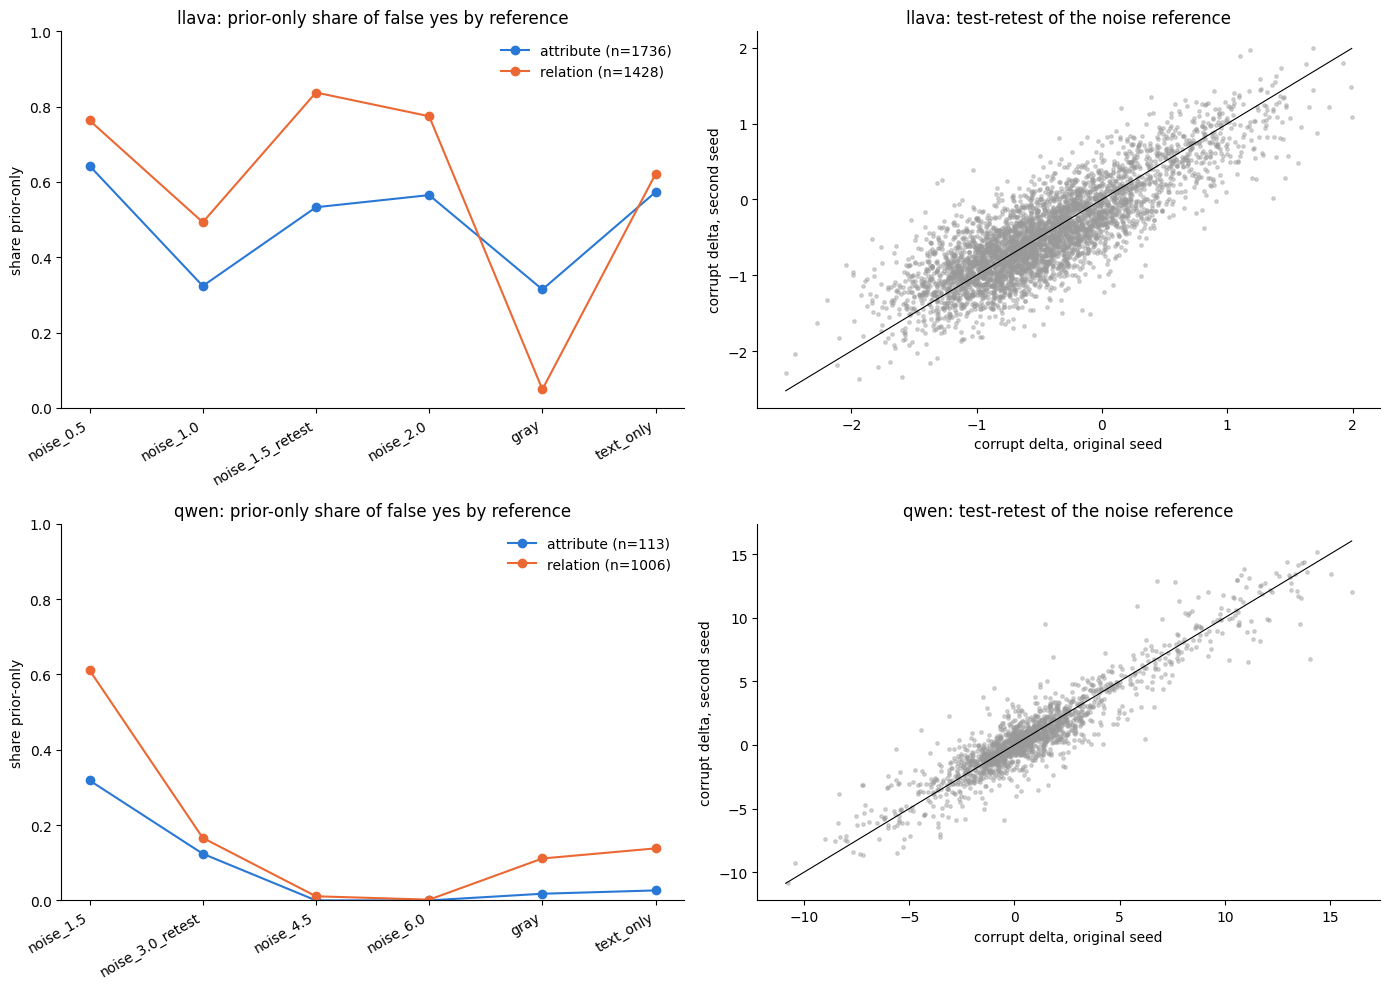

In [5]:
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#999999"
fig, axes = plt.subplots(len(FRAMES), 2, figsize=(14, 5 * len(FRAMES)), squeeze=False)
for row, (model_, d) in enumerate(FRAMES.items()):
    fy = d[d.stratum.eq("false_yes")]
    names = refs_of(d)
    ax = axes[row, 0]
    for t, color in zip(TYPES, (BLUE, ORANGE)):
        g = fy[fy.hallucination_type.eq(t)]
        if len(g) < 10:
            continue
        ys = [float(np.isin(assign(g.delta_clean.to_numpy(), g[c].to_numpy(), TAU), ["prior-only"]).mean()) for c in names]
        ax.plot(range(len(names)), ys, "o-", color=color, label=f"{t} (n={len(g)})")
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels([c.replace("delta_", "") for c in names], rotation=30, ha="right")
    ax.set_ylim(0, 1)
    ax.set_ylabel("share prior-only")
    ax.set_title(f"{model_}: prior-only share of false yes by reference")
    ax.legend(frameon=False)
    ax = axes[row, 1]
    base = d[d.delta_noise_original.notna()]
    retest = [c for c in names if "retest" in c][0]
    ax.scatter(base.delta_noise_original, base[retest], s=6, alpha=0.4, color=GREY)
    lim = [min(base.delta_noise_original.min(), base[retest].min()), max(base.delta_noise_original.max(), base[retest].max())]
    ax.plot(lim, lim, color="black", lw=0.8)
    ax.set_xlabel("corrupt delta, original seed")
    ax.set_ylabel("corrupt delta, second seed")
    ax.set_title(f"{model_}: test-retest of the noise reference")
for ax in axes.ravel():
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/modes_reference_stability.png", dpi=150)
plt.show()